# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Podemos convertir documentos escaneados y entrevistas en audio peruanas en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Estudiante** | RoddyHuarhua (@roddyhuarhua-hub) |
| **Fecha de extracción** | se imprime en la celda siguiente (ejecución del notebook) |
| **Documentos (corpus A)** | 25 imágenes de Wikimedia Commons: 8 impresos, 8 fotos con sombra o inclinación, 9 manuscritos. Licencias libres (CC BY, CC BY-SA, CC0 o dominio público), registradas archivo por archivo en `datos/fuentes.csv`. 9 de ellos son los que usó la Sesión 10; el resto sale de búsquedas en Commons. |
| **Audio (corpus B)** | OpenSLR 73 *Crowdsourced high-quality Peruvian Spanish speech* (Google, **CC BY-SA 4.0**), 20 clips de ~80 s de un solo hablante + 1 entrevista de 2 hablantes; y 3 entrevistas reales de Wikimedia Commons (**CC BY-SA 4.0**: El Agustino, Lima ×2; Aurora Coronado, Fenmucarinap). Atribución en `datos/fuentes.csv`. |
| **OCR** | PaddleOCR 3.x, PP-OCRv5, `lang="es"`, motor PyTorch (`engine="transformers"`), sin corrección de orientación ni "planchado" de página, CPU. |
| **ASR** | faster-whisper `small` (CTranslate2, int8, CPU), `language="es"`, `beam_size=5`, **VAD activado** (Silero), diarización con huellas WeSpeaker + clustering (voz.py, Sesión 13). |
| **Entorno** | versiones exactas en la celda siguiente. |

Los archivos originales se guardan en `datos/raw/` y **no** se suben a Git (ver `.gitignore`); `datos/fuentes.csv` explica cómo recuperarlos (`python -c "import t2; t2.recolectar_documentos(); t2.recolectar_audio()"`).

In [1]:
import sys, json, platform, datetime, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import plotly.express as px
from IPython.display import Image, display
import t2

pd.set_option("display.max_colwidth", 120)
FIGS = Path("figuras"); FIGS.mkdir(exist_ok=True)

def mostrar(fig, nombre):
    """Muestra el gráfico interactivo y además una copia PNG para que se vea en GitHub."""
    fig.write_html(FIGS / f"{nombre}.html", include_plotlyjs="cdn")
    try:
        fig.write_image(FIGS / f"{nombre}.png", width=900, height=450, scale=1)
        display(Image(filename=str(FIGS / f"{nombre}.png")))
    except Exception as e:
        print("(sin PNG estático:", type(e).__name__, ")")
    fig.show()

import importlib.metadata as md
def ver(p):
    try: return md.version(p)
    except Exception: return "no instalado"
print("Fecha de extracción:", datetime.date.today().isoformat())
print("Python", platform.python_version(), "|", platform.platform())
for p in ["paddleocr", "paddlex", "torch", "transformers", "faster-whisper", "ctranslate2", "pyannote.audio", "easyocr", "jiwer", "plotly"]:
    print(f"  {p:15s} {ver(p)}")

Fecha de extracción: 2026-10-26
Python 3.12.14 | Windows-11-10.0.26200-SP0
  paddleocr       3.7.0
  paddlex         3.7.2
  torch           2.14.1
  transformers    5.20.2
  faster-whisper  1.2.1
  ctranslate2     4.8.4
  pyannote.audio  4.0.7
  easyocr         1.7.2
  jiwer           4.0.0
  plotly          7.1.0


## 1. Corpus A: documentos
Se descargan con la API de Commons (User-Agent descriptivo, 1 s de pausa entre pedidos), versión de 1600 px de ancho. Solo se aceptan licencias libres; los duplicados se detectan por hash SHA-1 del archivo.

In [2]:
docs = t2.recolectar_documentos()
print("Documentos:", len(docs)); print(docs["tipo"].value_counts().to_string())
docs[["id", "tipo", "titulo_commons", "licencia"]]

Documentos: 25
tipo
manuscrito    9
impreso       8
foto          8


,id,tipo,titulo_commons,licencia
0,doc_001,impreso,Acta de Creación de los Símbolos para el Distrito de Mache.jpg,CC BY 4.0
1,doc_002,impreso,500000 Intis 1988(Front).jpg,CC0
2,doc_003,impreso,Pisco-punch-mercurio-peruano-1791.jpg,Public domain
3,doc_004,foto,Placa Calle Capon.jpg,CC BY 3.0
4,doc_005,foto,Cartel Picante de cuy.JPG,Public domain
5,doc_006,foto,Menu Levaggi 09052010.jpg,CC BY-SA 3.0
6,doc_007,manuscrito,Peruvian Telephone Company receipt Lima 1895.JPG,Public domain
7,doc_008,manuscrito,Tarjeta de Ricardo Palma a Luis Antonio Eguiguren Escudero 24 octubre 1912.png,Public domain
8,doc_009,manuscrito,Acta de Independencia Peru.jpg,Public domain
9,doc_010,impreso,Mercurio Peruano1.jpg,Public domain


In [3]:
try:
    desc_doc = pd.read_csv("datos/raw/documentos/descartes_descarga.csv")
except Exception:
    desc_doc = pd.DataFrame(columns=["archivo", "motivo"])
print("Candidatos descartados al descargar:", len(desc_doc))
desc_doc

Candidatos descartados al descargar: 12


,archivo,motivo
0,Mercurio peruano (1918) (14755475506).jpg,licencia no libre: No restrictions
1,Pedro Beltrán.jpg,revisión manual: no es un documento legible
2,Apolinario Mayta Inga 01.jpg,revisión manual: no es un documento legible
3,Apolinario Mayta Inga 02.jpg,revisión manual: no es un documento legible
4,Apolinario Mayta Inga 03.jpg,revisión manual: no es un documento legible
5,"Víctor Caballero ""Curwen"" - 2025.jpg",licencia no libre: Copyrighted free use
6,PRESIDENTE HUMALA Y MINISTRO CATERIANO DEVELARON PLACA CONMEMORATIVA DE LA DELIMITACIÓN MARÍTIMA CON CHILE.jpg,revisión manual: no es un documento legible
7,A Guiding Light to the Indians WDL8994.jpg,revisión manual: no es un documento legible
8,El primer nueva corónica y buen gobierno i KBs udstilling 27112012.JPG,revisión manual: no es un documento legible
9,Guaman Poma Nueva Coronica f. 1105v detail.jpg,revisión manual: no es un documento legible


## 2. Corpus B: audio
OpenSLR 73 se lee por partes (HTTP Range) con `datos_sesion13.py` (copia de `datos.py` de la Sesión 13): no se bajan los 900 MB de cada zip. Cada clip une 16 frases seguidas de **un mismo hablante**, con 0,5 s de silencio entre frases.

In [4]:
aud = t2.recolectar_audio()
print(f"Clips: {len(aud)} | minutos: {aud.duracion_seg.sum()/60:.1f} | multihablante: {(aud.n_hablantes_real == 2).sum()} + entrevistas reales")
aud[["id", "fuente", "condicion", "duracion_seg", "licencia"]]

Clips: 24 | minutos: 48.2 | multihablante: 1 + entrevistas reales


,id,fuente,condicion,duracion_seg,licencia
0,clip_001,OpenSLR 73 (Google),"leído, estudio, mujer",133.3,CC BY-SA 4.0
1,clip_002,OpenSLR 73 (Google),"leído, estudio, mujer",108.7,CC BY-SA 4.0
2,clip_003,OpenSLR 73 (Google),"leído, estudio, mujer",98.6,CC BY-SA 4.0
3,clip_004,OpenSLR 73 (Google),"leído, estudio, mujer",113.7,CC BY-SA 4.0
4,clip_005,OpenSLR 73 (Google),"leído, estudio, mujer",110.0,CC BY-SA 4.0
5,clip_006,OpenSLR 73 (Google),"leído, estudio, mujer",99.2,CC BY-SA 4.0
6,clip_007,OpenSLR 73 (Google),"leído, estudio, mujer",145.6,CC BY-SA 4.0
7,clip_008,OpenSLR 73 (Google),"leído, estudio, mujer",104.3,CC BY-SA 4.0
8,clip_009,OpenSLR 73 (Google),"leído, estudio, mujer",110.8,CC BY-SA 4.0
9,clip_010,OpenSLR 73 (Google),"leído, estudio, mujer",107.4,CC BY-SA 4.0


## 3. Limpieza: duplicados por hash y archivos sin contenido útil

In [5]:
import hashlib
dup_doc = docs[docs.duplicated("sha1")]
dup_aud = aud[aud.duplicated("sha1")]
print("Documentos duplicados por hash:", len(dup_doc), "| audios duplicados por hash:", len(dup_aud))

import voz
voz_seg = {}
for r in aud.itertuples():
    x = voz.cargar_audio(r.archivo_audio)
    voz_seg[r.id] = sum(b - a for a, b in voz.tramos_de_voz(x))
aud["segundos_con_voz"] = aud.id.map(voz_seg).round(1)
sin_voz = aud[aud.segundos_con_voz < 3]
print("Audios sin voz (VAD < 3 s de habla):", len(sin_voz))
aud = aud[~aud.id.isin(sin_voz.id) & ~aud.id.isin(dup_aud.id)].reset_index(drop=True)
aud[["id", "duracion_seg", "segundos_con_voz"]].T

Documentos duplicados por hash: 0 | audios duplicados por hash: 0


Audios sin voz (VAD < 3 s de habla): 0


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
id,clip_001,clip_002,clip_003,clip_004,clip_005,clip_006,clip_007,clip_008,clip_009,clip_010,...,clip_015,clip_016,clip_017,clip_018,clip_019,clip_020,clip_021,clip_022,clip_023,clip_024
duracion_seg,133.3,108.7,98.6,113.7,110.0,99.2,145.6,104.3,110.8,107.4,...,113.4,101.6,94.4,100.9,108.3,93.3,106.3,136.3,189.0,250.6
segundos_con_voz,58.5,44.2,50.6,62.4,53.9,48.8,62.6,58.5,58.4,65.7,...,46.6,49.4,53.5,56.5,50.4,55.4,48.4,105.5,156.6,239.5


## 4. OCR con PaddleOCR (los 25 documentos)
Respaldo crudo (texto, confianza, número de líneas y tiempo por página) en `datos/raw/documentos/ocr_paddle_base.json`.

In [6]:
rutas_doc = [Path(a) for a in docs.archivo]
ocr = t2.ocr_paddle(rutas_doc)
docs = docs.merge(ocr.rename(columns={"archivo": "nombre"}), left_on=docs.archivo.str.split("/").str[-1], right_on="nombre").drop(columns=["key_0", "nombre"], errors="ignore")
docs["n_caracteres"] = docs.texto.str.len()
print(f"Tiempo total OCR: {docs.segundos.sum():.0f} s ({docs.segundos.mean():.1f} s por página)")
docs[["id", "tipo", "n_lineas", "confianza_media", "n_caracteres", "segundos"]].round(2)

Tiempo total OCR: 366 s (14.7 s por página)


,id,tipo,n_lineas,confianza_media,n_caracteres,segundos
0,doc_001,impreso,28,0.99,1729,35.62
1,doc_002,impreso,14,0.93,159,10.08
2,doc_003,impreso,44,0.95,1669,25.70
3,doc_004,foto,9,0.92,59,18.88
4,doc_005,foto,0,0.00,0,9.04
5,doc_006,foto,22,0.93,286,12.92
6,doc_007,manuscrito,17,0.85,232,8.32
7,doc_008,manuscrito,12,0.90,542,20.62
8,doc_009,manuscrito,46,0.58,438,13.01
9,doc_010,impreso,32,0.90,1584,16.27


In [7]:
# Documentos ilegibles: menos de 20 caracteres reconocidos o confianza media < 0,5
ilegibles = docs[(docs.n_caracteres < 20) | (docs.confianza_media < 0.5)]
print("Documentos marcados como ilegibles:", len(ilegibles))
ilegibles[["id", "tipo", "titulo_commons", "n_caracteres", "confianza_media"]]

Documentos marcados como ilegibles: 1


,id,tipo,titulo_commons,n_caracteres,confianza_media
4,doc_005,foto,Cartel Picante de cuy.JPG,0,0.0


## 5. ASR con faster-whisper + VAD + diarización
Todos los clips con faster-whisper `small` en CPU y VAD. La diarización se aplica a los audios con más de un hablante: la entrevista de 2 hablantes de OpenSLR (de la que conocemos la verdad) y la entrevista callejera de El Agustino con dos vendedoras. Se exportan SRT y TXT por clip a `datos/raw/audio/salidas/`.

In [8]:
multi = list(aud[(aud.n_hablantes_real == 2) | aud.condicion.str.contains("dos vendedoras")].id)
print("Se diarizan:", multi)
asr = t2.asr_faster_whisper([Path(a) for a in aud.archivo_audio], "small", diarizar_ids=tuple(multi))
aud = aud.merge(asr.drop(columns=["duracion_seg"]), left_on=aud.archivo_audio.str.split("/").str[-1], right_on="archivo").drop(columns=["key_0", "archivo"], errors="ignore")
aud["rtf"] = (aud.segundos_proceso / aud.duracion_seg).round(3)
aud["n_palabras"] = aud.texto.str.split().str.len()
print(f"Audio transcrito: {aud.duracion_seg.sum()/60:.1f} min en {aud.segundos_proceso.sum()/60:.1f} min de CPU (RTF medio {aud.rtf.mean():.2f})")
aud[["id", "duracion_seg", "n_palabras", "n_hablantes", "rtf"]]

Se diarizan: ['clip_021', 'clip_023']
Audio transcrito: 48.2 min en 35.8 min de CPU (RTF medio 0.88)


,id,duracion_seg,n_palabras,n_hablantes,rtf
0,clip_001,133.3,150,NaN,0.088
1,clip_002,108.7,129,NaN,0.096
2,clip_003,98.6,149,NaN,0.144
3,clip_004,113.7,158,NaN,0.115
4,clip_005,110.0,138,NaN,0.101
5,clip_006,99.2,121,NaN,18.580
6,clip_007,145.6,155,NaN,0.071
7,clip_008,104.3,160,NaN,0.102
8,clip_009,110.8,181,NaN,0.091
9,clip_010,107.4,190,NaN,0.100


In [9]:
for i in multi:
    print(f"── {i}: diarización ({aud.set_index('id').n_hablantes[i]} hablantes detectados)")
    txt = Path(f"datos/raw/audio/salidas/fw_small/{i}.txt").read_text(encoding="utf-8")
    print(t2.seudonimizar(txt, t2.nombres_privados())[0][:700], "\n")  # ya seudonimizado (ver sección 6)

── clip_021: diarización (2.0 hablantes detectados)
[00:00:00] H1: La granizada destruyó toda plantación de lechuga.

[00:00:03] H2: Lo primero que tiene que hacer es mantener la calma.

[00:00:09] H1: Ayer llovió mucho y llegué tarde a mi reunión.

[00:00:15] H2: Es importante que manejes bien la letra E.

[00:00:21] H1: ¿Por qué dicen que la sal no es saludable?

[00:00:27] H2: Es muy fácil reguardar su hogar de los huracanes.

[00:00:33] H1: ¿Qué lugares románticos hay por aquí?

[00:00:43] H2: Es muy importante la parte gutural con la R.

[00:00:46] H1: En el Amazonas existen los insectos más venenosos.

[00:00:52] H2: En el trayecto van a ir acompañados de otros turistas.

[00:00:59] H1: ¿Qué tipo de tema le gustaría escuchar?

[00:01:05 

── clip_023: diarización (5.0 hablantes detectados)
[00:00:00] H1: Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer una entrevista acerca del fútbol como unión de masas. Estoy con las señoras. [PERSONA_2]. [PE

## 6. Seudonimización
Regla: se reemplazan DNI (8 dígitos), RUC, teléfonos celulares y correos, y los nombres de **personas privadas** que aparezcan (por ejemplo, vendedores entrevistados en la calle). Los nombres de figuras históricas o públicas que firman documentos públicos (Ricardo Palma, firmantes del Acta de Independencia) no son datos personales protegidos y se mantienen. La lista `NOMBRES_PRIVADOS` se completa después de **leer cada texto**: el método automático no reemplaza la revisión humana.

In [10]:
# Completar tras la revisión manual de los textos: {"Nombre real": "Seudónimo"}
# Lista {"Nombre real": "Seudónimo"} armada tras leer cada texto; vive en datos/raw/nombres_privados.json (fuera de Git).
# Revisión: las vecinas entrevistadas en la calle (clip_022 y clip_023) son personas privadas, también con las
# variantes que el ASR escribió mal. Aurora Coronado (clip_024) habla como representante de Fenmucarinap: se mantiene.
NOMBRES_PRIVADOS = t2.nombres_privados()
print("Nombres privados en la lista:", len(NOMBRES_PRIVADOS))
conteo = {}
for df, col in [(docs, "texto"), (aud, "texto")]:
    nuevos, ns = zip(*[t2.seudonimizar(t, NOMBRES_PRIVADOS) for t in df[col]])
    df[col] = list(nuevos); conteo[col + ("_ocr" if df is docs else "_asr")] = sum(ns)
    df["reemplazos"] = list(ns)
print("Entidades reemplazadas:", conteo)
print(pd.concat([docs.loc[docs.reemplazos > 0, ["id", "reemplazos"]], aud.loc[aud.reemplazos > 0, ["id", "reemplazos"]]]).to_string(index=False) or "ninguna")

Nombres privados en la lista: 5
Entidades reemplazadas: {'texto_ocr': 0, 'texto_asr': 10}
      id  reemplazos
clip_022           1
clip_023           9


## 7. Análisis exploratorio (Plotly Express)

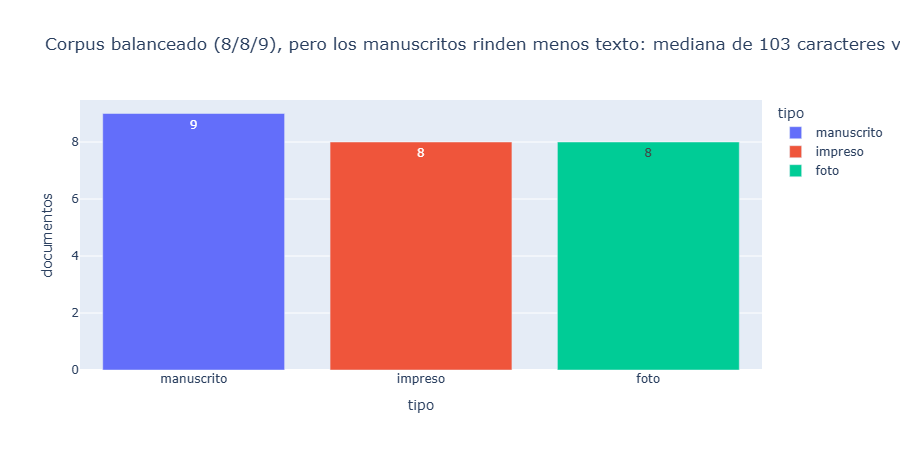

In [11]:
cuenta = docs.tipo.value_counts().rename_axis("tipo").reset_index(name="documentos")
ch = docs.groupby("tipo").n_caracteres.median()
titulo = f"Corpus balanceado (8/8/9), pero los {ch.idxmin()}s rinden menos texto: mediana de {ch.min():.0f} caracteres vs {ch.max():.0f} en {ch.idxmax()}s"
fig = px.bar(cuenta, x="tipo", y="documentos", text="documentos", title=titulo, color="tipo")
mostrar(fig, "g1_documentos_por_tipo")

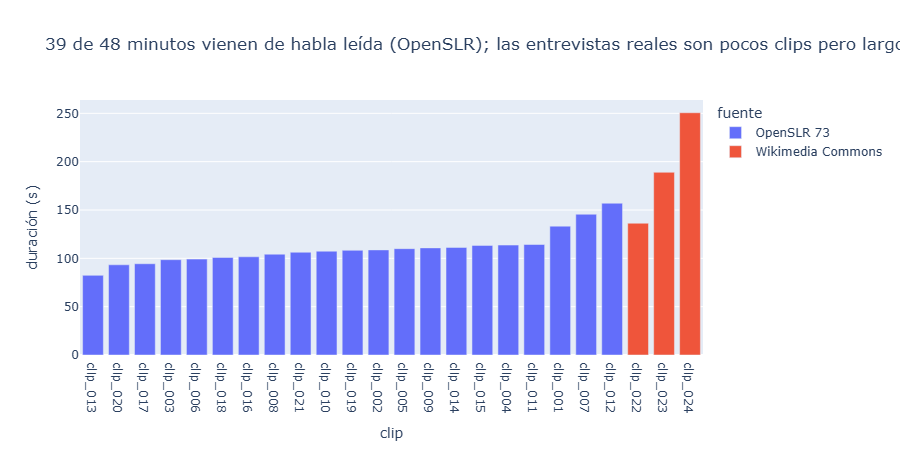

In [12]:
aud["fuente_corta"] = np.where(aud.fuente.str.startswith("OpenSLR"), "OpenSLR 73", "Wikimedia Commons")
m = aud.groupby("fuente_corta").duracion_seg.sum() / 60
titulo = f"{m.get('OpenSLR 73', 0):.0f} de {m.sum():.0f} minutos vienen de habla leída (OpenSLR); las entrevistas reales son pocos clips pero largos"
fig = px.bar(aud.sort_values("duracion_seg"), x="id", y="duracion_seg", color="fuente_corta", title=titulo,
             labels={"duracion_seg": "duración (s)", "id": "clip", "fuente_corta": "fuente"})
mostrar(fig, "g2_duracion_por_clip")

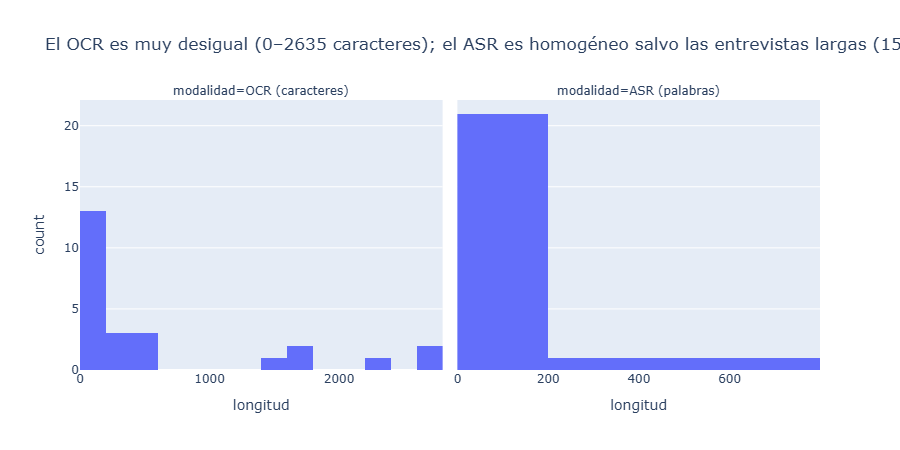

In [13]:
largo = pd.concat([pd.DataFrame({"modalidad": "OCR (caracteres)", "longitud": docs.n_caracteres}),
                   pd.DataFrame({"modalidad": "ASR (palabras)", "longitud": aud.n_palabras})])
titulo = (f"El OCR es muy desigual ({docs.n_caracteres.min()}–{docs.n_caracteres.max()} caracteres); "
          f"el ASR es homogéneo salvo las entrevistas largas ({aud.n_palabras.median():.0f} palabras de mediana)")
fig = px.histogram(largo, x="longitud", facet_col="modalidad", nbins=20, title=titulo)
fig.update_xaxes(matches=None)
mostrar(fig, "g3_longitud_textos")

## 8. Validación: extremos de cada corpus
Comprobamos que los extremos de los histogramas tienen sentido mirando el texto.

In [14]:
cols = ["id", "tipo", "n_caracteres", "confianza_media"]
print("OCR más largos"); display(docs.nlargest(3, "n_caracteres")[cols + ["texto"]])
print("OCR más cortos"); display(docs.nsmallest(3, "n_caracteres")[cols + ["texto"]])

OCR más largos


,id,tipo,n_caracteres,confianza_media,texto
11,doc_012,impreso,2635,0.952219,"euerpo: dirigen ácña todas partes sus miradas eon un desmayo afectado, y con tales ademanes que puedcn excitar la ri..."
10,doc_011,impreso,2607,0.898013,"1_ desa Trifaldi: á este tiempo llegaren de Sera sas-madmitas de exe jaez, levastándoss dei esuado À recibiries, eme..."
12,doc_013,impreso,2379,0.905844,"230 de heber tenido tan buen discernimiento, que haya merecido probacion Dios guarde á- Vms. muchos afios. Chitrade..."


OCR más cortos


,id,tipo,n_caracteres,confianza_media,texto
4,doc_005,foto,0,0.000000,
22,doc_023,manuscrito,57,0.810334,120 LAPRIMERAHISDELAREVASO TORiA MAMAVACOCOIA QGUGuyuLD A
3,doc_004,foto,59,0.923927,Baby Boy BARRIO CHINO GAS HELIO CALLE 10 CAPON BACKYARDI 50


In [15]:
cols = ["id", "condicion", "duracion_seg", "n_palabras"]
print("Clips más largos"); display(aud.nlargest(3, "duracion_seg")[cols + ["texto"]])
print("Clips más cortos"); display(aud.nsmallest(3, "duracion_seg")[cols + ["texto"]])

Clips más largos


,id,condicion,duracion_seg,n_palabras,texto
23,clip_024,entrevista real: Dirigente de Fenmucarinap (sierra central) durante una conferencia de prensa (2022),250.6,632,"Bueno, hola, estamos en los San Martín, entre Fritas Patreas, 28 de julio. Entonces, primero, ¿podría comenzarme dic..."
22,clip_023,"entrevista real: Entrevista en la calle a dos vendedoras de dulces, mismo día",189.0,410,[HABLANTE_1] Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a [HABLANTE_1] hacer una e...
11,clip_012,"leído, estudio, hombre",157.0,189,"Quiero irme de vacaciones a Hawaii, pero tengo esta duda de si el volcán está activo. Todas las apuestas han quedado..."


Clips más cortos


,id,condicion,duracion_seg,n_palabras,texto
12,clip_013,"leído, estudio, hombre",82.4,182,Los hamsters comenzan a orias. Te veo muy alegre y eso me parece maravilloso. ¿Quiere que le proporcione la direcció...
19,clip_020,"leído, estudio, hombre",93.3,132,¿Quién dirige la película? Estoy muy mareado. La granizada destruyó toda la plantación de lechuga. ¿Buscas vivir sol...
16,clip_017,"leído, estudio, hombre",94.4,127,Apague el motor del coche y ponga el freno de mano. Tiene que reportar inmediatamente el accidente para que lo cubra...


## 9. Exportación a CSV

In [16]:
documentos = pd.DataFrame({
    "id": docs.id, "archivo": docs.archivo, "tipo": docs.tipo,
    "fuente": "Wikimedia Commons (" + docs.licencia + ")",
    "texto_ocr": docs.texto,
    "modelo_ocr": "PaddleOCR " + ver("paddleocr") + " PP-OCRv5 (lang=es, engine=transformers, CPU, sin orientación/unwarping)",
    "texto_referencia": "",
})
transcripciones = pd.DataFrame({
    "id": aud.id, "archivo_audio": aud.archivo_audio, "duracion_seg": aud.duracion_seg,
    "idioma": "es (variante peruana documentada por la fuente)", "texto_asr": aud.texto,
    "modelo_asr": "faster-whisper " + ver("faster-whisper") + " small (int8, CPU, VAD on, beam 5)",
    "n_hablantes": aud.n_hablantes.fillna(1).astype(int), "texto_referencia": "",
})
fuentes = pd.concat([
    pd.DataFrame({"id": docs.id, "modalidad": "documento", "fuente_url": docs.fuente_url, "licencia": docs.licencia,
                  "autor": docs.autor, "acceso": "API de Commons; t2.recolectar_documentos() (ancho 1600 px)"}),
    pd.DataFrame({"id": aud.id, "modalidad": "audio", "fuente_url": aud.fuente_url, "licencia": aud.licencia,
                  "autor": aud.fuente, "acceso": "t2.recolectar_audio() (OpenSLR por HTTP Range; Commons Special:FilePath)"}),
])
documentos.to_csv("datos/documentos.csv", index=False)
transcripciones.to_csv("datos/transcripciones.csv", index=False)
fuentes.to_csv("datos/fuentes.csv", index=False)
aud[["id", "referencia_dataset", "condicion", "fuente_corta", "rtf", "segundos_proceso"]].to_csv("datos/raw/audio/meta_clips.csv", index=False)
for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(nombre, df.shape)
documentos.head()

documentos (25, 7)
transcripciones (24, 8)
fuentes (49, 6)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (CC BY 4.0),SERESUELVE: .- Artículo 1°- RECONOCER como lema ganador en el Concurso Público Creación del Lema para el Distrito de...,"PaddleOCR 3.7.0 PP-OCRv5 (lang=es, engine=transformers, CPU, sin orientación/unwarping)",
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (CC0),BANCO CENTRAL DE RESERUADELPERU 500000 A4962929H S QUINIENTOS MILINTIS RICARDOPALMA ae 85 21 DE DICIEMBRE DE 1988 DI...,"PaddleOCR 3.7.0 PP-OCRv5 (lang=es, engine=transformers, CPU, sin orientación/unwarping)",
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (Public domain),Eol. 25. MERCURIO PERUANO DEL DIA 13. DE ENERO DE 1791. の EXAMEN HISTÓRICO DE LAS DIVERSIONES PÚBLICAS de las Nacion...,"PaddleOCR 3.7.0 PP-OCRv5 (lang=es, engine=transformers, CPU, sin orientación/unwarping)",
3,doc_004,datos/raw/documentos/doc_004.jpg,foto,Wikimedia Commons (CC BY 3.0),Baby Boy BARRIO CHINO GAS HELIO CALLE 10 CAPON BACKYARDI 50,"PaddleOCR 3.7.0 PP-OCRv5 (lang=es, engine=transformers, CPU, sin orientación/unwarping)",
4,doc_005,datos/raw/documentos/doc_005.jpg,foto,Wikimedia Commons (Public domain),,"PaddleOCR 3.7.0 PP-OCRv5 (lang=es, engine=transformers, CPU, sin orientación/unwarping)",


In [17]:
transcripciones.head()

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.wav,133.3,es (variante peruana documentada por la fuente),"Hasta que no acabe es la tarea, no puedes salir con tus amigos. El chicle se conoció en México durante la invasión g...","faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5)",1,
1,clip_002,datos/raw/audio/clip_002.wav,108.7,es (variante peruana documentada por la fuente),¿Cuál es el periódico más importante? Los niños tienen mucha imaginación. No te entiendo nada. Los corazones de poll...,"faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5)",1,
2,clip_003,datos/raw/audio/clip_003.wav,98.6,es (variante peruana documentada por la fuente),Tú tienes que encargarte de todo eso. Quiero la computadora para estar en contacto con mi equipo de trabajo. ¿Hay al...,"faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5)",1,
3,clip_004,datos/raw/audio/clip_004.wav,113.7,es (variante peruana documentada por la fuente),La tienda de jabones y perfumes finos tienen regalos para el día de las madres. El director González Iñárritu es un ...,"faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5)",1,
4,clip_005,datos/raw/audio/clip_005.wav,110.0,es (variante peruana documentada por la fuente),No me gustan los bares donde hay poca gente. Los zapatos se estropearon con la lluvia torrencial de ayer. No me gust...,"faster-whisper 1.2.1 small (int8, CPU, VAD on, beam 5)",1,


In [18]:
fuentes.head()

,id,modalidad,fuente_url,licencia,autor,acceso
0,doc_001,documento,https://commons.wikimedia.org/wiki/File:Acta_de_Creaci%C3%B3n_de_los_S%C3%ADmbolos_para_el_Distrito_de_Mache.jpg,CC BY 4.0,Helder Zavaleta Verde,API de Commons; t2.recolectar_documentos() (ancho 1600 px)
1,doc_002,documento,https://commons.wikimedia.org/wiki/File:500000_Intis_1988(Front).jpg,CC0,ByRussia45,API de Commons; t2.recolectar_documentos() (ancho 1600 px)
2,doc_003,documento,https://commons.wikimedia.org/wiki/File:Pisco-punch-mercurio-peruano-1791.jpg,Public domain,El Mercurio Peruano,API de Commons; t2.recolectar_documentos() (ancho 1600 px)
3,doc_004,documento,https://commons.wikimedia.org/wiki/File:Placa_Calle_Capon.jpg,CC BY 3.0,Miguel Angel Chong,API de Commons; t2.recolectar_documentos() (ancho 1600 px)
4,doc_005,documento,https://commons.wikimedia.org/wiki/File:Cartel_Picante_de_cuy.JPG,Public domain,Dtarazona,API de Commons; t2.recolectar_documentos() (ancho 1600 px)


In [19]:
# Ejemplos publicables para el dashboard (licencia libre, sin datos personales): todas las imágenes reducidas y 6 clips cortos
from PIL import Image as PImg
import soundfile as sf
(t2.EJEMPLOS / "img").mkdir(exist_ok=True); (t2.EJEMPLOS / "audio").mkdir(exist_ok=True)
for r in docs.itertuples():
    im = PImg.open(r.archivo).convert("RGB"); im.thumbnail((900, 900)); im.save(t2.EJEMPLOS / "img" / f"{r.id}.jpg", quality=80)
# Solo clips de OpenSLR: en las entrevistas de Commons se oyen los nombres reales de las vecinas.
for i in aud.id[:3].tolist() + aud.id[10:13].tolist() + [m for m in multi if aud.set_index("id").fuente_corta[m] == "OpenSLR 73"]:
    x, sr = sf.read(f"datos/raw/audio/{i}.wav"); t2.guardar_ogg(x[: 45 * sr], sr, t2.EJEMPLOS / "audio" / f"{i}.ogg")
print(sum(p.stat().st_size for p in t2.EJEMPLOS.rglob("*") if p.is_file()) / 1e6, "MB en datos/ejemplos/")

4.035573 MB en datos/ejemplos/
